# Sesión 3 · Taller: visualización exploratoria
**Misión 9–11 nov 2026 · Lunes 9 · segunda mitad (~45 min)**

Eres analista de un restaurante. Con `tips` debes responder **qué determina la propina**. Completa las celdas `# TODO` (reemplaza `...`). Todo se vio en la demo.

| Ejercicio | Tema | Min |
|---|---|---|
| 1 | Elegir el gráfico correcto | 4 |
| 2 | Distribución de `tip_pct` | 6 |
| 3 | `tip_pct` por grupo: boxplot y violin | 6 |
| 4 | Barras: conteos y proporciones | 7 |
| 5 | Scatter y bubble | 5 |
| 6 | Correlaciones + mapa de calor | 6 |
| 7 | Pairplot | 6 |
| 8 | Gráfico interactivo + 3 hallazgos | 5 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
tips = sns.load_dataset("tips")
DIAS = ["Thur", "Fri", "Sat", "Sun"]
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Ejercicio 1 · ¿Qué gráfico usarías?
Completa la tabla (doble clic en esta celda):

| Pregunta | Gráfico |
|---|---|
| ¿Cómo se distribuye el monto de la cuenta? | … |
| ¿Qué día hay más cuentas? | … |
| ¿Cambia el % de propina entre almuerzo y cena? | … |
| ¿Las mesas grandes dejan más propina? | … |
| ¿Qué tan relacionadas están todas las variables numéricas? | … |

## Ejercicio 2 · Distribución del % de propina
Crea la columna `tip_pct` = 100 × tip / total_bill y grafica su histograma con KDE. Agrega una línea vertical en la **mediana**.

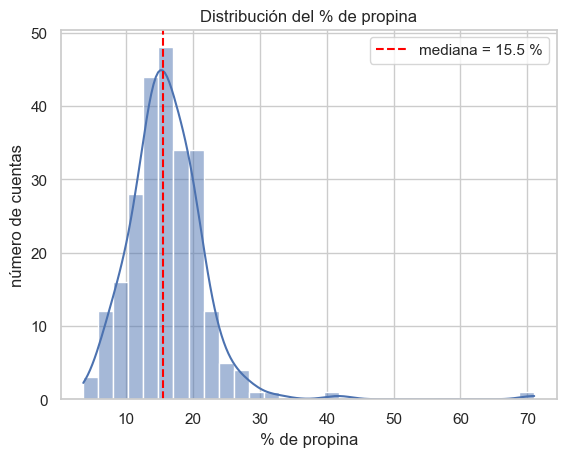

In [2]:
tips["tip_pct"] = 100 * tips["tip"] / tips["total_bill"]  # TODO
mediana = tips["tip_pct"].median()      # TODO

ax = sns.histplot(tips, x="tip_pct", kde=True, bins=30)  # TODO: sns.histplot con kde=True y bins=30
ax.axvline(mediana, color="red", ls="--", label=f"mediana = {mediana:.1f} %")
ax.set(xlabel="% de propina", ylabel="número de cuentas", title="Distribución del % de propina")
ax.legend(); plt.show()

**Pregunta:** ¿hay valores atípicos? ¿Cuál es el más extremo y qué crees que pasó en esa mesa?

*Tu respuesta:* …

## Ejercicio 3 · % de propina por grupo
En una figura de 1×2: **boxplot** de `tip_pct` por `day` (en orden `DIAS`) y **violin** de `tip_pct` por `time`.

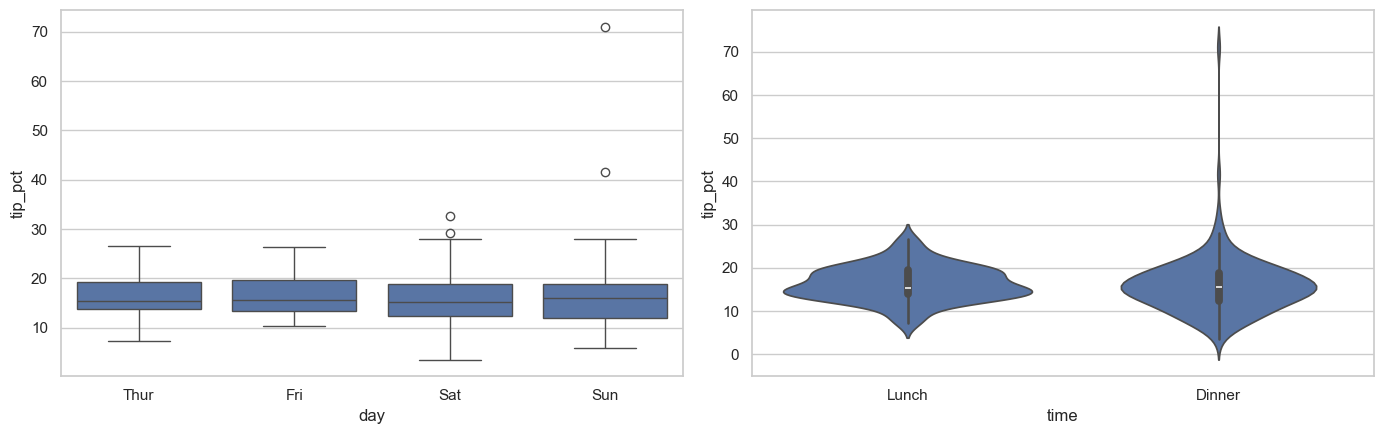

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(tips, x="day", y="tip_pct", order=DIAS, ax=axes[0]) # TODO: boxplot en axes[0]
sns.violinplot(tips, x="time", y="tip_pct", ax=axes[1]) # TODO: violinplot en axes[1] con x="time"
plt.tight_layout(); plt.show()

## Ejercicio 4 · Barras: conteos y proporciones
a) Barras **horizontales** con el **% de propina promedio** por día, ordenadas de mayor a menor.
b) Tabla cruzada `day` × `time` y gráfico de barras **100 % apiladas**.

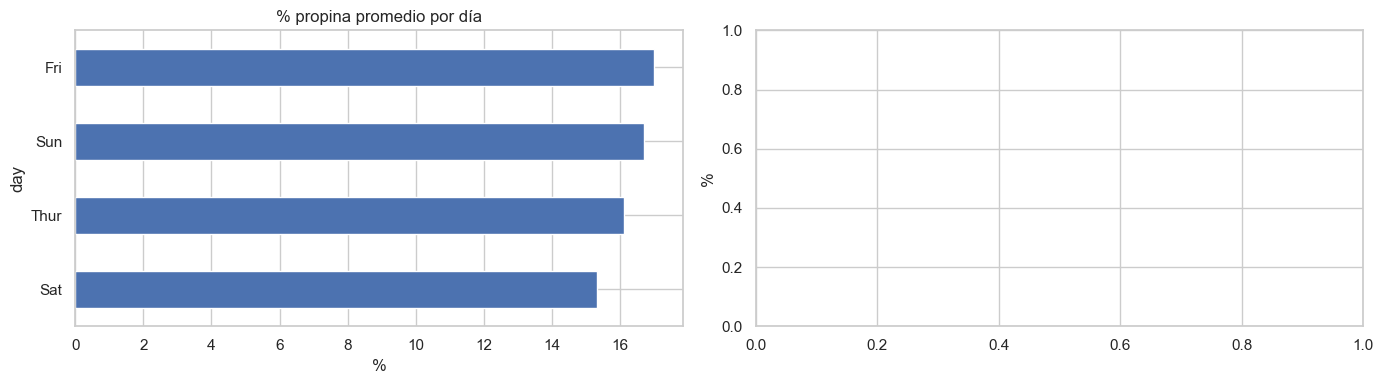

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
prom = tips.groupby("day", observed=True)["tip_pct"].mean().sort_values()  # TODO: promedio de tip_pct por day (groupby, observed=True), ordenado
prom.plot.barh(ax=axes[0], color="#4C72B0", title="% propina promedio por día")
axes[0].set_xlabel("%")

tabla = pd.crosstab(tips["day"], tips["time"]).reindex(DIAS)  # TODO: pd.crosstab de day × time, reindexado con DIAS
# TODO: convierte cada fila a porcentaje y grafica barras apiladas en axes[1]
axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Pregunta:** ¿por qué en (b) conviene mostrar porcentajes y no conteos?

*Tu respuesta:* …

## Ejercicio 5 · Scatter y bubble
Grafica `total_bill` vs `tip` con color por `time` y tamaño por `size` (número de comensales).

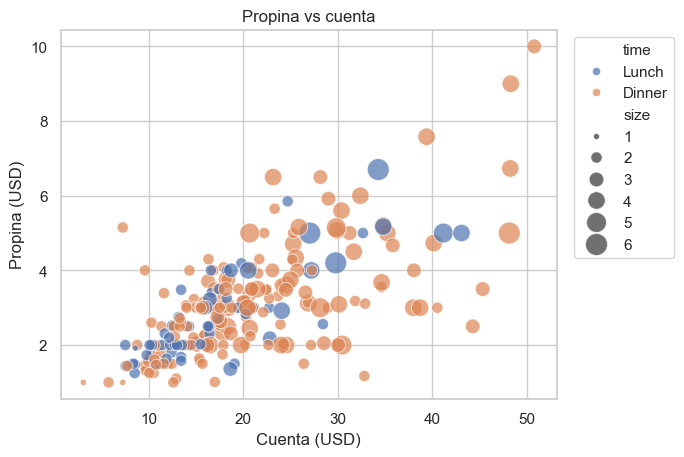

In [5]:
ax = sns.scatterplot(tips, x="total_bill", y="tip", hue="time", size="size", sizes=(20, 250), alpha=0.7)  # TODO: sns.scatterplot con hue="time", size="size", sizes=(20, 250), alpha=0.7
ax.set(xlabel="Cuenta (USD)", ylabel="Propina (USD)", title="Propina vs cuenta")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

## Ejercicio 6 · Correlaciones
Calcula la correlación entre `["total_bill", "tip", "size", "tip_pct"]` y dibújala como **mapa de calor** con los valores escritos (`annot=True`).

In [ ]:
cols = ["total_bill", "tip", "size", "tip_pct"]
corr = ...  # TODO: tips[cols].corr()
# TODO: sns.heatmap con annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1
plt.title("Correlaciones en tips"); plt.show()

**Pregunta:** ¿qué dos variables están más relacionadas? `tip_pct` y `total_bill` tienen correlación **negativa**: ¿significa que la gente con cuentas grandes es tacaña? Propón otra explicación.

*Tu respuesta:* …

## Ejercicio 7 · Pairplot
Dibuja un `sns.pairplot` de `cols` coloreando por `time` (almuerzo / cena).

In [ ]:
# TODO: sns.pairplot(tips[cols + ["time"]], hue="time", height=2.2)
plt.show()

## Ejercicio 8 · Gráfico interactivo y hallazgos
Con Plotly Express crea un scatter de `total_bill` vs `tip_pct`, color por `day`, facetas por `time` (`facet_col`) y `hover_data` con `size` y `smoker`. Ponle un **título que sea un hallazgo** y guárdalo como `tips_interactivo.html`.

In [ ]:
fig = ...  # TODO: px.scatter con color, facet_col, hover_data, labels y un título-hallazgo
fig.write_html("tips_interactivo.html")
fig.show()

### Tus 3 hallazgos (específicos, cuantificados y prudentes)
1. …
2. …
3. …

**Una cosa que estos datos NO permiten concluir:** …